300 300 72.0


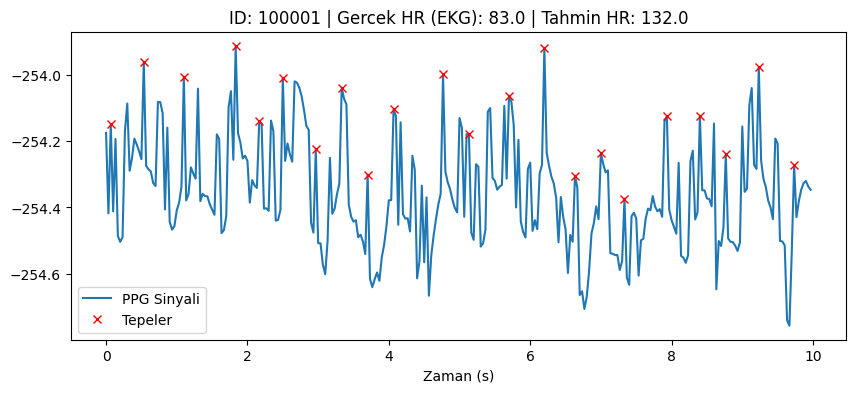

In [38]:
!pip install wfdb

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import wfdb
import pandas as pd

def oku(i):
    s = wfdb.rdrecord(f'{i}_PPG', pn_dir=f'butppg/2.0.0/{i}').p_signal
    return s.ravel() if s.shape[0] == 1 else s[:, 0]

def hr_ham(x):
    p = find_peaks(x, distance=10)[0]
    return (len(p) * 60 / (len(x) / 30), p)

# Sağlama kontrolü
print(len(oku(100001)), len(oku(132004)), hr_ham(np.sin(2 * np.pi * 1.2 * np.arange(300) / 30))[0])

# d veri çerçevesinin tanımlı olup olmadığını kontrol et
try:
    d
except NameError:
    print("'d' değişkeni bulunamadı. CSV dosyalarından doğrudan yüklenmeye çalışılıyor...")
    try:
        ann = pd.read_csv('quality-hr-ann.csv')
        subj = pd.read_csv('subject-info.csv')
        df = pd.merge(ann, subj, on='ID')
        d = df[(df['Ear/finger'] == 1) & (df['Quality'] == 1)].head(100).copy()
    except Exception as e:
        raise NameError("Lütfen önce '32b9e277' hücresini çalıştırın veya CSV dosyalarının yüklü olduğundan emin olun.") from e

# İlk kayıt ve şekil çizimi
i, hr = d['ID'].iloc[0], d['HR'].iloc[0]
x = oku(i)
tahmin, p = hr_ham(x)
t = np.arange(len(x)) / 30

plt.figure(figsize=(10, 4))
plt.plot(t, x, label='PPG Sinyali')
plt.plot(t[p], x[p], 'rx', label='Tepeler')
plt.xlabel('Zaman (s)')
plt.title(f'ID: {i} | Gercek HR (EKG): {hr:.1f} | Tahmin HR: {tahmin:.1f}')
plt.legend()
plt.savefig('sekil1.png')
plt.show()

In [39]:
import pandas as pd

# PhysioNet'ten gerçek CSV dosyalarını indirmek için wget kullanıyoruz veya doğrudan doğru ham bağlantıları hedefliyoruz.
# Eğer doğrudan erişimde izin/protokol engeli varsa, tarayıcıdan indirilip Colab'e yüklenmesi en sağlıklı yoldur.
try:
    # Ham (raw) dosya bağlantılarını wget ile indiriyoruz (PhysioNet bazen doğrudan pandas üzerinden HTML döndürür)
    !wget -q https://physionet.org/files/butppg/2.0.0/quality-hr-ann.csv -O quality-hr-ann.csv
    !wget -q https://physionet.org/files/butppg/2.0.0/subject-info.csv -O subject-info.csv

    ann = pd.read_csv('quality-hr-ann.csv')
    subj = pd.read_csv('subject-info.csv')

    # ID sütunları üzerinden birleştir
    df = pd.merge(ann, subj, on='ID')

    # Ear/finger == 1 (parmak) ve Quality == 1 (kaliteli) ilk 100 kaydı filtrele
    d = df[(df['Ear/finger'] == 1) & (df['Quality'] == 1)].head(100).copy()

    print('Tablodaki kayıt sayısı:', len(d))
    print(d[['ID', 'HR']].head())
except Exception as e:
    print("Dosyalar indirilirken hata oluştu. Lütfen CSV dosyalarını bilgisayarınıza indirip Colab sol menüsünden yükleyin.")
    print("Hata detayı:", e)

Tablodaki kayıt sayısı: 100
       ID  HR
0  100001  83
1  100002  85
2  100003  81
4  101001  67
5  101002  69


In [40]:
import pandas as pd

N = 100
sonuclar = []

for _, row in d.head(N).iterrows():
    ID = int(row['ID'])
    HR = row['HR']
    x = oku(ID)
    assert len(x) == 300, ID
    tahmin = hr_ham(x)[0]
    hata = abs(tahmin - HR)
    sonuclar.append({
        'ID': ID,
        'HR_ekg': HR,
        'HR_ham': tahmin,
        'hata': hata
    })

s = pd.DataFrame(sonuclar)
s.to_csv('baseline.csv', index=False)

print('Kayıt sayısı:', len(s))
print(f"Baseline MAE (atım/dk) = {s['hata'].mean():.2f}")
print(f"Hata<5 yüzdesi = {(s['hata'] < 5).mean() * 100:.0f}")

Kayıt sayısı: 100
Baseline MAE (atım/dk) = 36.18
Hata<5 yüzdesi = 5


Kayıt sayısı: 100
Fazla sayılan (f > 0): 97
Eksik sayılan (f < 0): 2
Eşit sayılan (f == 0): 1
En yüksek hatalı 3 kayıt:
        ID  HR_ekg  HR_ham  hata
7   102002      66   132.0  66.0
5   101003      71   132.0  61.0
65  133007      54   114.0  60.0


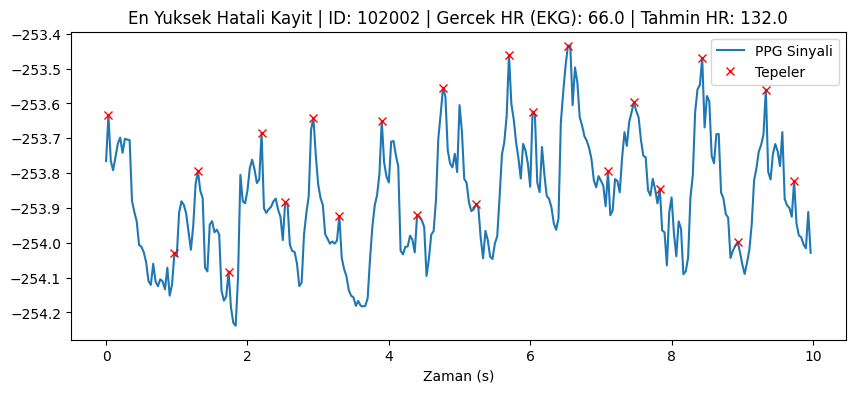

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

s = pd.read_csv('baseline.csv')
print('Kayıt sayısı:', len(s))

f = s['HR_ham'] - s['HR_ekg']
print('Fazla sayılan (f > 0):', (f > 0).sum())
print('Eksik sayılan (f < 0):', (f < 0).sum())
print('Eşit sayılan (f == 0):', (f == 0).sum())

e = s.nlargest(3, 'hata')
print('En yüksek hatalı 3 kayıt:')
print(e)

ilk_id = int(e['ID'].iloc[0])
ilk_hr = e['HR_ekg'].iloc[0]

x = oku(ilk_id)
tahmin, p = hr_ham(x)
t = np.arange(len(x)) / 30

plt.figure(figsize=(10, 4))
plt.plot(t, x, label='PPG Sinyali')
plt.plot(t[p], x[p], 'rx', label='Tepeler')
plt.xlabel('Zaman (s)')
plt.title(f'En Yuksek Hatali Kayit | ID: {ilk_id} | Gercek HR (EKG): {ilk_hr:.1f} | Tahmin HR: {tahmin:.1f}')
plt.legend()
plt.show()

İncelenen Kayıt ID: 100001
Örnekleme Frekansı (fs): 30 Hz


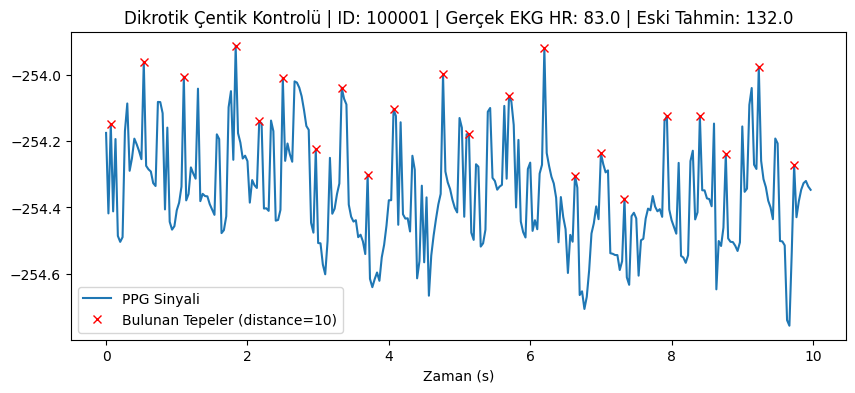

In [42]:
import wfdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# 1. Baseline tablosundan tahminin EKG'den yüksek olduğu (fazla sayılan) ilk kaydı seçme
s = pd.read_csv('baseline.csv')
fazla_sayilanlar = s[s['HR_ham'] > s['HR_ekg']]
ornek_id = int(fazla_sayilanlar.iloc[0]['ID'])

# 2. wfdb kütüphanesi ile ilgili kaydın üst verisini çekip örnekleme frekansını yazdırma
record = wfdb.rdrecord(f'{ornek_id}_PPG', pn_dir=f'butppg/2.0.0/{ornek_id}')
fs = record.fs
print(f"İncelenen Kayıt ID: {ornek_id}")
print(f"Örnekleme Frekansı (fs): {fs} Hz")

# 3. Önceden tanımladığınız oku() fonksiyonu ile sinyali çekme
x = oku(ornek_id)

# 4. Eski yöntemle (distance=10) tepeleri tekrar bulma
p = find_peaks(x, distance=10)[0]
t = np.arange(len(x)) / fs

# 5. Sinyali ve bulunan tepeleri çizdirme
plt.figure(figsize=(10, 4))
plt.plot(t, x, label='PPG Sinyali')
plt.plot(t[p], x[p], 'rx', label='Bulunan Tepeler (distance=10)')
plt.xlabel('Zaman (s)')
plt.title(f'Dikrotik Çentik Kontrolü | ID: {ornek_id} | Gerçek EKG HR: {fazla_sayilanlar.iloc[0]["HR_ekg"]} | Eski Tahmin: {fazla_sayilanlar.iloc[0]["HR_ham"]}')
plt.legend()
plt.show()

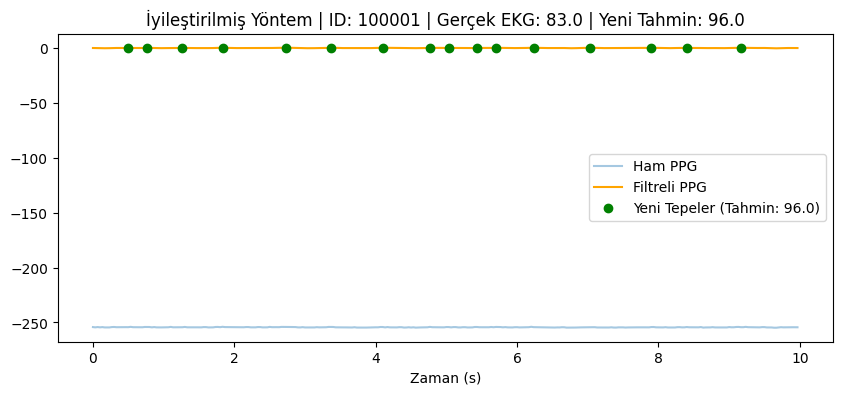

In [43]:
from scipy.signal import butter, filtfilt, find_peaks

# 1. İyileştirilmiş nabız hesaplama fonksiyonu
def hr_yeni(x, fs=30):
    # 0.5 Hz (30 bpm) ile 4.0 Hz (240 bpm) arası bant geçiren filtre
    b, a = butter(2, [0.5, 4.0], btype='bandpass', fs=fs)
    x_filt = filtfilt(b, a, x)

    # Makul en yüksek nabız (ör. 220 atım/dk) için minimum tepe mesafesi
    # distance = fs / (220 / 60) = 30 / 3.66 = ~8.18 -> 8 örnek
    min_mesafe = 8

    # Sinyalin kendi tepe-çukur farkına göre dinamik çıkıntı (prominence) eşiği
    esik_prom = (np.max(x_filt) - np.min(x_filt)) * 0.15

    # Yeni parametrelerle tepe bulma
    p = find_peaks(x_filt, distance=min_mesafe, prominence=esik_prom)[0]
    nabiz = len(p) * 60 / (len(x) / fs)

    return nabiz, p, x_filt

# 2. Yeni yöntemi aynı sorunlu kayıtta (ornek_id) deneme ve çizdirme
tahmin_yeni, p_yeni, x_filt = hr_yeni(x, fs)

plt.figure(figsize=(10, 4))
plt.plot(t, x, label='Ham PPG', alpha=0.4)
plt.plot(t, x_filt, label='Filtreli PPG', color='orange')
plt.plot(t[p_yeni], x_filt[p_yeni], 'go', label=f'Yeni Tepeler (Tahmin: {tahmin_yeni:.1f})')
plt.xlabel('Zaman (s)')
plt.title(f'İyileştirilmiş Yöntem | ID: {ornek_id} | Gerçek EKG: {fazla_sayilanlar.iloc[0]["HR_ekg"]} | Yeni Tahmin: {tahmin_yeni:.1f}')
plt.legend()
plt.show()

In [44]:
import pandas as pd
import numpy as np

# 1. Baseline tablosunu okuma
s = pd.read_csv('baseline.csv')

# 2. Kayıt ID'sinden kişi kodunu çıkarma
# (BUT PPG veri setinde ID'lerin ilk kısmı kişiyi belirtir, 1000'e bölerek alabiliriz)
s['Kisi_ID'] = s['ID'] // 1000

# 3. Benzersiz kişileri bulup karıştırma
kisiler = s['Kisi_ID'].unique()
np.random.seed(42) # Her çalıştırmada aynı ayrımı almak için
np.random.shuffle(kisiler)

# 4. Kişileri iki gruba ayırma (Yarısı ayar grubu, yarısı test grubu)
orta_nokta = len(kisiler) // 2
ayar_kisileri = kisiler[:orta_nokta]
test_kisileri = kisiler[orta_nokta:]

# 5. Veriyi bu kişilere göre parçalama
ayar_seti = s[s['Kisi_ID'].isin(ayar_kisileri)].copy()
test_seti = s[s['Kisi_ID'].isin(test_kisileri)].copy()

# 6. Test setini sonraki son adım (kıyaslama) için kaydetme
test_seti.to_csv('test_seti.csv', index=False)

# 7. Ayrım sonuçlarını ve doğrulamayı yazdırma
print(f"Toplam benzersiz kişi: {len(kisiler)}")
print(f"Ayar grubu kayıt sayısı: {len(ayar_seti)} | Kişiler: {ayar_kisileri}")
print(f"Test grubu kayıt sayısı: {len(test_seti)} | Kişiler: {test_kisileri}")

# 8. Aynı kişinin iki tarafta da olmadığının kesin kontrolü
ortak_kisi = set(ayar_kisileri).intersection(set(test_kisileri))
print(f"İki grupta da olan ortak kişi sayısı: {len(ortak_kisi)}")

Toplam benzersiz kişi: 14
Ayar grubu kayıt sayısı: 43 | Kişiler: [109 111 100 132 105 108 102]
Test grubu kayıt sayısı: 57 | Kişiler: [101 133 104 107 110 103 106]
İki grupta da olan ortak kişi sayısı: 0


In [45]:
import pandas as pd
import numpy as np

# 1. Test setini yükleme
test_df = pd.read_csv('test_seti.csv')

yeni_tahminler = []
yeni_hatalar = []

# 2. Test setindeki her kayıt için yeni yöntemi hesaplama
for _, row in test_df.iterrows():
    kayit_id = int(row['ID'])
    hr_ekg = row['HR_ekg']

    x = oku(kayit_id)
    # Yeni fonksiyondan sadece nabız tahminini alıyoruz (ilk eleman: indeks 0)
    nabiz_yeni = hr_yeni(x, fs=30)[0]

    yeni_tahminler.append(nabiz_yeni)
    yeni_hatalar.append(abs(nabiz_yeni - hr_ekg))

# 3. Sonuçları tabloya yeni sütunlar olarak kaydetme
test_df['HR_yeni'] = yeni_tahminler
test_df['hata_yeni'] = yeni_hatalar

# 4. Yönlü hataları (tahmin - gerçek) bulma
f_eski = test_df['HR_ham'] - test_df['HR_ekg']
f_yeni = test_df['HR_yeni'] - test_df['HR_ekg']

# 5. Sonuçları karşılaştırmalı olarak ekrana yazdırma
print(f"--- TEST SETİ SONUÇLARI ({len(test_df)} Kayıt) ---")
print(f"Eski (Baseline) MAE: {test_df['hata'].mean():.2f}")
print(f"Yeni (Filtreli) MAE: {test_df['hata_yeni'].mean():.2f}")
print("-" * 30)
print(f"Eski Hata < 5 Yüzdesi: %{(test_df['hata'] < 5).mean() * 100:.0f}")
print(f"Yeni Hata < 5 Yüzdesi: %{(test_df['hata_yeni'] < 5).mean() * 100:.0f}")
print("-" * 30)
print(f"Eski Fazla (f>0): {(f_eski > 0).sum()} | Eksik (f<0): {(f_eski < 0).sum()} | Eşit: {(f_eski == 0).sum()}")
print(f"Yeni Fazla (f>0): {(f_yeni > 0).sum()} | Eksik (f<0): {(f_yeni < 0).sum()} | Eşit: {(f_yeni == 0).sum()}")

--- TEST SETİ SONUÇLARI (57 Kayıt) ---
Eski (Baseline) MAE: 33.98
Yeni (Filtreli) MAE: 8.30
------------------------------
Eski Hata < 5 Yüzdesi: %7
Yeni Hata < 5 Yüzdesi: %60
------------------------------
Eski Fazla (f>0): 54 | Eksik (f<0): 2 | Eşit: 1
Yeni Fazla (f>0): 17 | Eksik (f<0): 34 | Eşit: 6


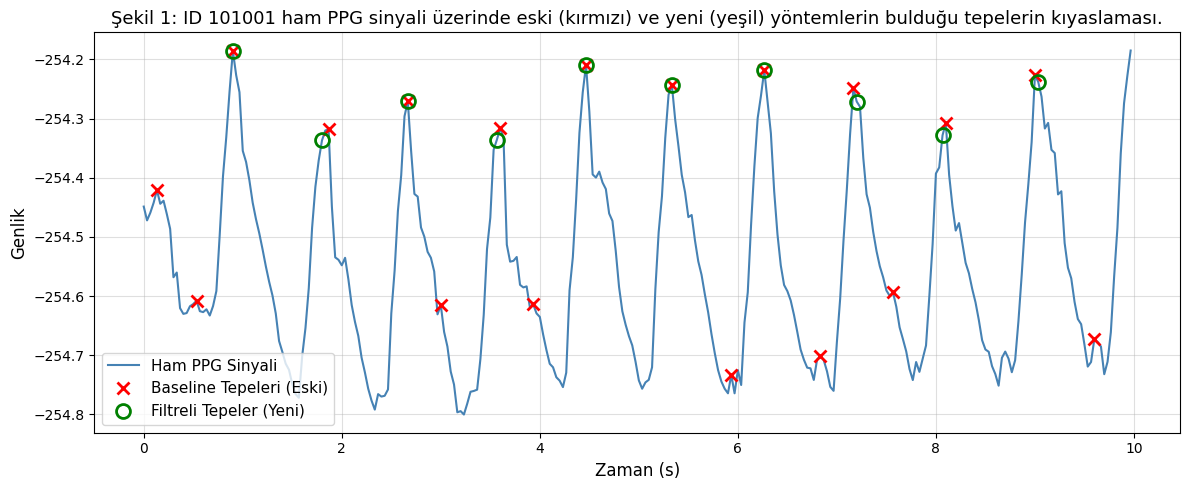

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

# 1. Test setinden ilk kaydı okuma ve zaman eksenini oluşturma (fs=30)
test_df = pd.read_csv('test_seti.csv')
gorsel_id = int(test_df.iloc[0]['ID'])
x = oku(gorsel_id)
t = np.arange(len(x)) / 30

# 2. Eski (baseline) ve yeni yöntemle tepe noktalarını hesaplama
p_eski = find_peaks(x, distance=10)[0]
_, p_yeni, _ = hr_yeni(x, fs=30)

# 3. Çizim alanı ve sinyal grafikleri
plt.figure(figsize=(12, 5))
plt.plot(t, x, label='Ham PPG Sinyali', color='steelblue', linewidth=1.5)
plt.plot(t[p_eski], x[p_eski], 'rx', markersize=8, markeredgewidth=2, label='Baseline Tepeleri (Eski)')
plt.plot(t[p_yeni], x[p_yeni], 'go', markersize=10, markerfacecolor='none', markeredgewidth=2, label='Filtreli Tepeler (Yeni)')

# 4. Eksen adları, okunur yazı boyutu ve tek cümlelik açıklama (başlık)
plt.xlabel('Zaman (s)', fontsize=12)
plt.ylabel('Genlik', fontsize=12)
plt.title(f'Şekil 1: ID {gorsel_id} ham PPG sinyali üzerinde eski (kırmızı) ve yeni (yeşil) yöntemlerin bulduğu tepelerin kıyaslaması.', fontsize=13)
plt.legend(fontsize=11)
plt.grid(alpha=0.4)
plt.tight_layout()

# 5. Resmi kaydedip ekranda gösterme
plt.savefig('sekil1.png', dpi=300)
plt.show()

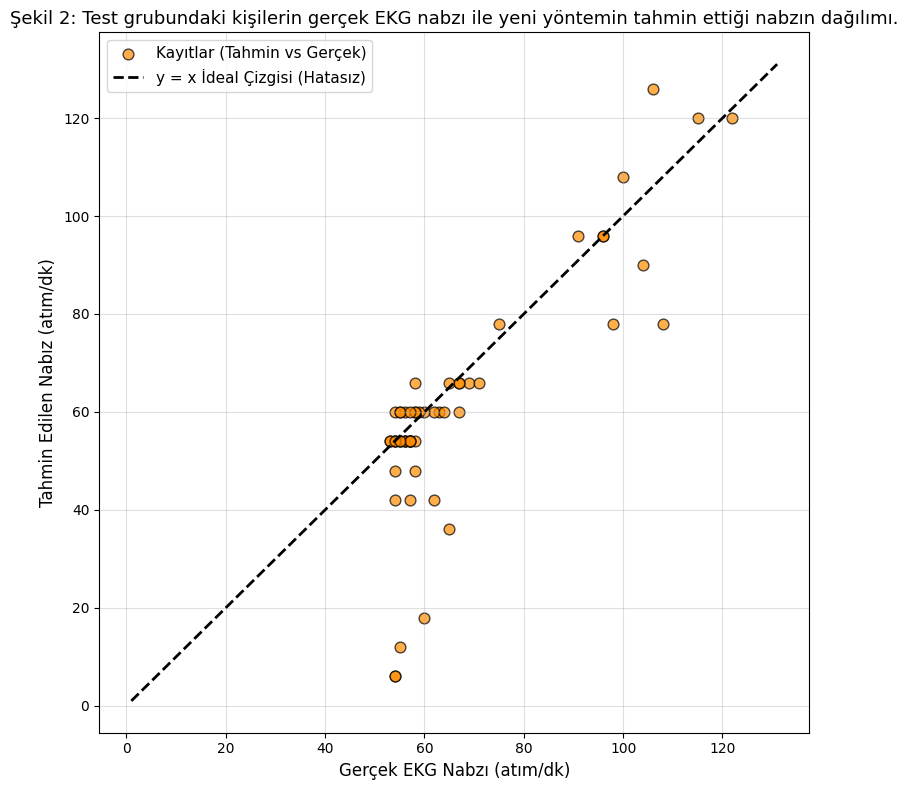

In [50]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Eğer bellekte güncel test_df varsa onu doğrudan kullan, yoksa diskten oku ve hesapla
try:
    # Bellekteki güncel tabloyu kullanmayı dene
    df_to_use = test_df
    if 'HR_yeni' not in df_to_use.columns:
        raise NameError()
except (NameError, KeyError):
    # Bellekte yoksa diskten oku ve 'HR_yeni' sütununu hızlıca hesapla
    df_to_use = pd.read_csv('test_seti.csv')
    yeni_tahminler = []
    for _, row in df_to_use.iterrows():
        x = oku(int(row['ID']))
        yeni_tahminler.append(hr_yeni(x, fs=30)[0])
    df_to_use['HR_yeni'] = yeni_tahminler

# 2. Gerçek ve yeni tahmin edilen nabız değerlerini alma
gercek_hr = df_to_use['HR_ekg']
tahmin_hr = df_to_use['HR_yeni']

# 3. Çizim alanını kareye yakın oluşturma ve saçılım grafiği
plt.figure(figsize=(8, 8))
plt.scatter(gercek_hr, tahmin_hr, color='darkorange', alpha=0.7, edgecolors='k', s=60, label='Kayıtlar (Tahmin vs Gerçek)')

# 4. İdeal durumu (sıfır hata) gösteren y = x referans çizgisini ekleme
min_val = min(gercek_hr.min(), tahmin_hr.min()) - 5
max_val = max(gercek_hr.max(), tahmin_hr.max()) + 5
plt.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, label='y = x İdeal Çizgisi (Hatasız)')

# 5. Eksen adları, birimler, okunur yazı boyutu ve tek cümlelik açıklama
plt.xlabel('Gerçek EKG Nabzı (atım/dk)', fontsize=12)
plt.ylabel('Tahmin Edilen Nabız (atım/dk)', fontsize=12)
plt.title('Şekil 2: Test grubundaki kişilerin gerçek EKG nabzı ile yeni yöntemin tahmin ettiği nabzın dağılımı.', fontsize=13)
plt.legend(fontsize=11)
plt.grid(alpha=0.4)
plt.tight_layout()

# 6. Resmi kaydedip ekranda gösterme (Eski sekil2.png'nin üzerine yazılacak)
plt.savefig('sekil2.png', dpi=300)
plt.show()

'hata_yeni' sütunu bulunamadı. Eksik sütunlar yeniden hesaplanıyor...


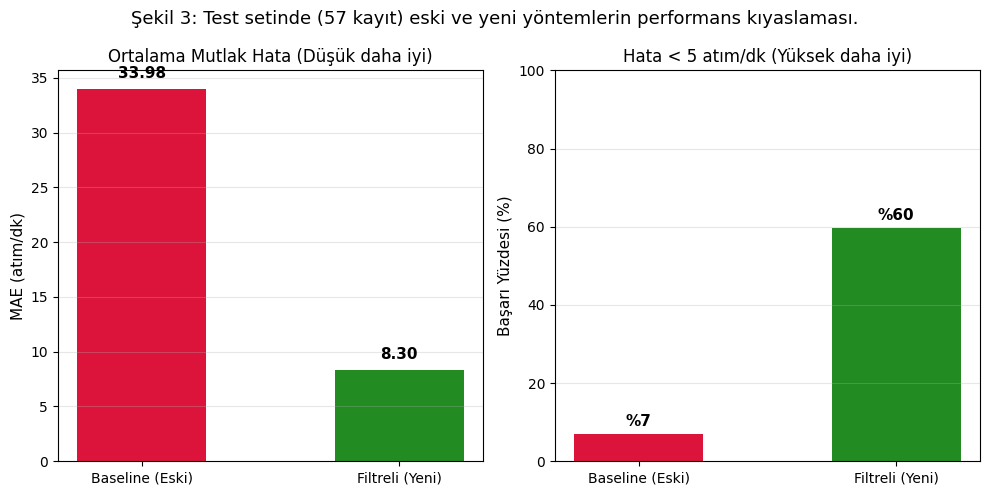

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Eğer 'hata_yeni' sütunu test_df içinde yoksa, otomatik olarak yeniden hesapla
if 'test_df' not in globals() or 'hata_yeni' not in test_df.columns:
    print("'hata_yeni' sütunu bulunamadı. Eksik sütunlar yeniden hesaplanıyor...")
    test_df = pd.read_csv('test_seti.csv')
    yeni_tahminler = []
    yeni_hatalar = []
    for _, row in test_df.iterrows():
        kayit_id = int(row['ID'])
        hr_ekg = row['HR_ekg']
        x = oku(kayit_id)
        nabiz_yeni = hr_yeni(x, fs=30)[0]
        yeni_tahminler.append(nabiz_yeni)
        yeni_hatalar.append(abs(nabiz_yeni - hr_ekg))
    test_df['HR_yeni'] = yeni_tahminler
    test_df['hata_yeni'] = yeni_hatalar

# Metrikleri hesaplama
mae_eski = test_df['hata'].mean()
mae_yeni = test_df['hata_yeni'].mean()
hata5_eski = (test_df['hata'] < 5).mean() * 100
hata5_yeni = (test_df['hata_yeni'] < 5).mean() * 100

# 2. Yan yana 2 alt grafikli çizim alanı oluşturma
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
yontemler = ['Baseline (Eski)', 'Filtreli (Yeni)']
renkler = ['crimson', 'forestgreen']

# 3. İlk grafik: MAE (Ortalama Mutlak Hata)
bars1 = ax1.bar(yontemler, [mae_eski, mae_yeni], color=renkler, width=0.5)
ax1.set_ylabel('MAE (atım/dk)', fontsize=11)
ax1.set_title('Ortalama Mutlak Hata (Düşük daha iyi)', fontsize=12)
ax1.grid(axis='y', alpha=0.3)

# Sütunların tepesine MAE değerlerini (sayıları) yazdırma
for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{bar.get_height():.2f}', ha='center', fontsize=11, fontweight='bold')

# 4. İkinci grafik: Hata < 5 Başarı Yüzdesi
bars2 = ax2.bar(yontemler, [hata5_eski, hata5_yeni], color=renkler, width=0.5)
ax2.set_ylabel('Başarı Yüzdesi (%)', fontsize=11)
ax2.set_title('Hata < 5 atım/dk (Yüksek daha iyi)', fontsize=12)
ax2.set_ylim(0, 100) # Yüzde olduğu için Y eksenini 0-100 arası sabitleme
ax2.grid(axis='y', alpha=0.3)

# Sütunların tepesine yüzde değerlerini yazdırma
for bar in bars2:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             f'%{bar.get_height():.0f}', ha='center', fontsize=11, fontweight='bold')

# 5. Genel başlık, kenar boşlukları ve kaydetme
plt.suptitle('Şekil 3: Test setinde (57 kayıt) eski ve yeni yöntemlerin performans kıyaslaması.', fontsize=13)
plt.tight_layout()
plt.savefig('sekil3.png', dpi=300)
plt.show()